<a href="https://colab.research.google.com/github/LucaCasallas/taller-pandas-olimpiadas-grupo-n/blob/6-10-Ejercicios/Proyecto_Colab_actualizado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Proyecto final Programación II
Por: Jerónimo Casallas, Ian García y Sebastián Martinez

## Creación de data frames

In [ ]:
# DATA FRAME ATLETAS
from google.colab import drive

drive.mount('/content/drive')

import pandas as pd

atletas = pd.read_csv(
    '/content/drive/MyDrive/Proyecto/athlete_events.csv'
)
atletas.tail()

Mounted at /content/drive


,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal
271111,135569,Andrzej ya,M,29.0,179.0,89.0,Poland-1,POL,1976 Winter,1976,Winter,Innsbruck,Luge,Luge Mixed (Men)'s Doubles,NaN
271112,135570,Piotr ya,M,27.0,176.0,59.0,Poland,POL,2014 Winter,2014,Winter,Sochi,Ski Jumping,"Ski Jumping Men's Large Hill, Individual",NaN
271113,135570,Piotr ya,M,27.0,176.0,59.0,Poland,POL,2014 Winter,2014,Winter,Sochi,Ski Jumping,"Ski Jumping Men's Large Hill, Team",NaN
271114,135571,Tomasz Ireneusz ya,M,30.0,185.0,96.0,Poland,POL,1998 Winter,1998,Winter,Nagano,Bobsleigh,Bobsleigh Men's Four,NaN
271115,135571,Tomasz Ireneusz ya,M,34.0,185.0,96.0,Poland,POL,2002 Winter,2002,Winter,Salt Lake City,Bobsleigh,Bobsleigh Men's Four,NaN


In [ ]:
# DATA FRAME REGIONES
regiones = pd.read_csv(
   '/content/drive/MyDrive/Proyecto/country_definitions.csv', sep=';'
)
display(regiones)

,NOC,region,notes
0,AFG,Afghanistan,NaN
1,AHO,Curacao,Netherlands Antilles
2,ALB,Albania,NaN
3,ALG,Algeria,NaN
4,AND,Andorra,NaN
...,...,...,...
225,YEM,Yemen,NaN
226,YMD,Yemen,South Yemen
227,YUG,Serbia,Yugoslavia
228,ZAM,Zambia,NaN


Debido al formato del archivo .csv, se tuvo que especificar que separara los datos con **;**, ya que de forma predeterminada, Python los separa por **,**.

## Descripción de las variables de los data sets
Haciendo uso de .describe(), se crea un data set mostrando las estadísticas descriptivas de cada data frame.

In [ ]:
# ESTADÍSTICAS GENERALES
display(atletas.describe().round(2))

,ID,Age,Height,Weight,Year
count,271116.00,261642.00,210945.00,208241.00,271116.00
mean,68248.95,25.56,175.34,70.70,1978.38
std,39022.29,6.39,10.52,14.35,29.88
min,1.00,10.00,127.00,25.00,1896.00
25%,34643.00,21.00,168.00,60.00,1960.00
50%,68205.00,24.00,175.00,70.00,1988.00
75%,102097.25,28.00,183.00,79.00,2002.00
max,135571.00,97.00,226.00,214.00,2016.00


In [ ]:
display(regiones.describe().round(2))

,NOC,region,notes
count,230,227,21
unique,230,206,21
top,AFG,Germany,Netherlands Antilles
freq,1,4,1


## Nueva columna: *IMC*
A través de las operaciones entre columnas de pandas, se ha creado la columna **IMC**.

In [ ]:
# COLUMNA IMC
atletas['IMC'] = atletas['Weight'] / (atletas['Height']/100)**2
display(atletas.tail())

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal,IMC
271111,135569,Andrzej ya,M,29.0,179.0,89.0,Poland-1,POL,1976 Winter,1976,Winter,Innsbruck,Luge,Luge Mixed (Men)'s Doubles,NaN,27.776911
271112,135570,Piotr ya,M,27.0,176.0,59.0,Poland,POL,2014 Winter,2014,Winter,Sochi,Ski Jumping,"Ski Jumping Men's Large Hill, Individual",NaN,19.047004
271113,135570,Piotr ya,M,27.0,176.0,59.0,Poland,POL,2014 Winter,2014,Winter,Sochi,Ski Jumping,"Ski Jumping Men's Large Hill, Team",NaN,19.047004
271114,135571,Tomasz Ireneusz ya,M,30.0,185.0,96.0,Poland,POL,1998 Winter,1998,Winter,Nagano,Bobsleigh,Bobsleigh Men's Four,NaN,28.049671
271115,135571,Tomasz Ireneusz ya,M,34.0,185.0,96.0,Poland,POL,2002 Winter,2002,Winter,Salt Lake City,Bobsleigh,Bobsleigh Men's Four,NaN,28.049671


In [ ]:
# atletas['IMC'] = atletas['IMC'].fillna('Sin datos')
# atletas

### ¿Que opina de esta nueva variable? ¿Tiene el mismo sentido en todos los deportes?
No, puesto que el rendimiento de los distintos deportes se ve afectado por las características físicas de los atletas. Además, hay valores ideales 'IMC' para obtener el mejor desempeño en distintos deportes. Por ejemplo, una persona delgada no va a desempeñarse igual haciendo atletismo que levantando pesas.

## Fusión de ambos data frames
Utilizando .merge(), se han fusionado ambos data frames tomando como referencia la variable 'NOC', que se encuentra en ambos data frames.

In [ ]:
# FUSIÓN AMBOS DATASETS
df_fusion = pd.merge(atletas, regiones , on='NOC', how='left')
df_fusion.sort_values(by= 'ID' , ascending= True)

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal,IMC,region,notes
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN,24.691358,China,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN,20.761246,China,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN,NaN,Denmark,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold,NaN,Denmark,NaN
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,NaN,23.959094,Netherlands,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
271111,135569,Andrzej ya,M,29.0,179.0,89.0,Poland-1,POL,1976 Winter,1976,Winter,Innsbruck,Luge,Luge Mixed (Men)'s Doubles,NaN,27.776911,Poland,NaN
271112,135570,Piotr ya,M,27.0,176.0,59.0,Poland,POL,2014 Winter,2014,Winter,Sochi,Ski Jumping,"Ski Jumping Men's Large Hill, Individual",NaN,19.047004,Poland,NaN
271113,135570,Piotr ya,M,27.0,176.0,59.0,Poland,POL,2014 Winter,2014,Winter,Sochi,Ski Jumping,"Ski Jumping Men's Large Hill, Team",NaN,19.047004,Poland,NaN
271114,135571,Tomasz Ireneusz ya,M,30.0,185.0,96.0,Poland,POL,1998 Winter,1998,Winter,Nagano,Bobsleigh,Bobsleigh Men's Four,NaN,28.049671,Poland,NaN


In [ ]:
# display(df_fusion[df_fusion['Medal'] == 'Bronze'])

In [ ]:
# FILAS CON NaN en NOC
display(df_fusion[df_fusion['region'].isna()])

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal,IMC,region,notes
578,332,Zarinah Abdullah,F,21.0,NaN,NaN,Singapore,SGP,1992 Summer,1992,Summer,Barcelona,Badminton,Badminton Women's Singles,NaN,NaN,NaN,NaN
579,332,Zarinah Abdullah,F,25.0,NaN,NaN,Singapore,SGP,1996 Summer,1996,Summer,Atlanta,Badminton,Badminton Women's Singles,NaN,NaN,NaN,NaN
2719,1515,Saiyidah Aisyah Mohamed Rafa'ee,F,28.0,173.0,68.0,Singapore,SGP,2016 Summer,2016,Summer,Rio de Janeiro,Rowing,Rowing Women's Single Sculls,NaN,22.720438,NaN,NaN
6267,3515,Paulo Amotun Lokoro,M,24.0,170.0,61.0,Refugee Olympic Athletes,ROT,2016 Summer,2016,Summer,Rio de Janeiro,Athletics,"Athletics Men's 1,500 metres",NaN,21.107266,NaN,Refugee Olympic Team
7659,4264,Ang Peng Siong,M,21.0,180.0,75.0,Singapore,SGP,1984 Summer,1984,Summer,Los Angeles,Swimming,Swimming Men's 100 metres Freestyle,NaN,23.148148,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
268752,134454,Zhang Guirong,F,26.0,182.0,95.0,Singapore,SGP,2004 Summer,2004,Summer,Athina,Athletics,Athletics Women's Shot Put,NaN,28.680111,NaN,NaN
268753,134454,Zhang Guirong,F,30.0,182.0,95.0,Singapore,SGP,2008 Summer,2008,Summer,Beijing,Athletics,Athletics Women's Shot Put,NaN,28.680111,NaN,NaN
268993,134587,Zhang Xueling,F,21.0,163.0,53.0,Singapore,SGP,2004 Summer,2004,Summer,Athina,Table Tennis,Table Tennis Women's Singles,NaN,19.948060,NaN,NaN
268994,134587,Zhang Xueling,F,21.0,163.0,53.0,Singapore-1,SGP,2004 Summer,2004,Summer,Athina,Table Tennis,Table Tennis Women's Doubles,NaN,19.948060,NaN,NaN


### ¿Cuántas filas quedan sin region? ¿Por qué cree que ocurre esto?
Por que en el dataframe de regiones, los valores 'TUV', 'ROT' y 'UNK' no tienen un valor en la columna 'NOC' por lo que llenan con NaN.

### ¿Qué tipo de fusión 'how' se usó? ¿Porque?
Usamos how='left'. Este tipo de fusión garantiza que el df de la izquierda(atletas) mantenga intactas todas sus filas incluso si algún atleta tiene un codigo NOC que no aparece en regiones.
##### Además, se descartan aquellos valores que se encuentren en el data frame 'regiones' que no tengan coincidencia con ninguna fila del data frame 'atletas'.

## Nueva columna: Medalla
Haciendo uso de .apply(), creamos la columna 'Medalla', que indica si un atleta ganó alguna medalla (ya sea de oro, plata o bronce). Esto lo hicimos limpiando los valores nulos de la columna 'Medal' y creando la función 'validarMedalla'.

In [ ]:
# LIMPIEZA DE LA COLUMNA "MEDAL"
df_fusion['Medal'] = df_fusion['Medal'].fillna('Ninguna')
df_fusion

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal,IMC,region,notes
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Ninguna,24.691358,China,NaN
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,Ninguna,20.761246,China,NaN
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,Ninguna,NaN,Denmark,NaN
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold,NaN,Denmark,NaN
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,Ninguna,23.959094,Netherlands,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
271111,135569,Andrzej ya,M,29.0,179.0,89.0,Poland-1,POL,1976 Winter,1976,Winter,Innsbruck,Luge,Luge Mixed (Men)'s Doubles,Ninguna,27.776911,Poland,NaN
271112,135570,Piotr ya,M,27.0,176.0,59.0,Poland,POL,2014 Winter,2014,Winter,Sochi,Ski Jumping,"Ski Jumping Men's Large Hill, Individual",Ninguna,19.047004,Poland,NaN
271113,135570,Piotr ya,M,27.0,176.0,59.0,Poland,POL,2014 Winter,2014,Winter,Sochi,Ski Jumping,"Ski Jumping Men's Large Hill, Team",Ninguna,19.047004,Poland,NaN
271114,135571,Tomasz Ireneusz ya,M,30.0,185.0,96.0,Poland,POL,1998 Winter,1998,Winter,Nagano,Bobsleigh,Bobsleigh Men's Four,Ninguna,28.049671,Poland,NaN


In [ ]:
# CREACIÓN COLUMNA "MEDALLA"
def validarMedalla(x):
  if x == 'Ninguna':
    return 0
  return 1

In [ ]:
df_fusion['Medalla'] = df_fusion['Medal'].apply(validarMedalla)
df_fusion

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal,IMC,region,notes,Medalla
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,Ninguna,24.691358,China,NaN,0
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,Ninguna,20.761246,China,NaN,0
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,Ninguna,NaN,Denmark,NaN,0
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold,NaN,Denmark,NaN,1
4,5,Christine Jacoba Aaftink,F,21.0,185.0,82.0,Netherlands,NED,1988 Winter,1988,Winter,Calgary,Speed Skating,Speed Skating Women's 500 metres,Ninguna,23.959094,Netherlands,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
271111,135569,Andrzej ya,M,29.0,179.0,89.0,Poland-1,POL,1976 Winter,1976,Winter,Innsbruck,Luge,Luge Mixed (Men)'s Doubles,Ninguna,27.776911,Poland,NaN,0
271112,135570,Piotr ya,M,27.0,176.0,59.0,Poland,POL,2014 Winter,2014,Winter,Sochi,Ski Jumping,"Ski Jumping Men's Large Hill, Individual",Ninguna,19.047004,Poland,NaN,0
271113,135570,Piotr ya,M,27.0,176.0,59.0,Poland,POL,2014 Winter,2014,Winter,Sochi,Ski Jumping,"Ski Jumping Men's Large Hill, Team",Ninguna,19.047004,Poland,NaN,0
271114,135571,Tomasz Ireneusz ya,M,30.0,185.0,96.0,Poland,POL,1998 Winter,1998,Winter,Nagano,Bobsleigh,Bobsleigh Men's Four,Ninguna,28.049671,Poland,NaN,0


In [ ]:
# MEDALLAS POR JUGADOR
display(df_fusion.groupby(['ID','Name'])['Medalla'].sum().sort_values(ascending=False))
# display(contar_medallas.sort_values(ascending=False))

,,Medalla
ID,Name,
94406,"Michael Fred Phelps, II",28
67046,Larysa Semenivna Latynina (Diriy-),18
4198,Nikolay Yefimovich Andrianov,15
74420,Edoardo Mangiarotti,13
109161,Borys Anfiyanovych Shakhlin,13
...,...,...
135570,Piotr ya,0
135552,Jan (Johann-) Zybert (Siebert-),0
135551,Vladislavas Zybaila,0


In [ ]:
df_fusion[df_fusion['Name'] == 'Michael Fred Phelps, II']

,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal,IMC,region,notes,Medalla
187887,94406,"Michael Fred Phelps, II",M,15.0,193.0,91.0,United States,USA,2000 Summer,2000,Summer,Sydney,Swimming,Swimming Men's 200 metres Butterfly,Ninguna,24.430186,USA,NaN,0
187888,94406,"Michael Fred Phelps, II",M,19.0,193.0,91.0,United States,USA,2004 Summer,2004,Summer,Athina,Swimming,Swimming Men's 200 metres Freestyle,Bronze,24.430186,USA,NaN,1
187889,94406,"Michael Fred Phelps, II",M,19.0,193.0,91.0,United States,USA,2004 Summer,2004,Summer,Athina,Swimming,Swimming Men's 4 x 100 metres Freestyle Relay,Bronze,24.430186,USA,NaN,1
187890,94406,"Michael Fred Phelps, II",M,19.0,193.0,91.0,United States,USA,2004 Summer,2004,Summer,Athina,Swimming,Swimming Men's 4 x 200 metres Freestyle Relay,Gold,24.430186,USA,NaN,1
187891,94406,"Michael Fred Phelps, II",M,19.0,193.0,91.0,United States,USA,2004 Summer,2004,Summer,Athina,Swimming,Swimming Men's 100 metres Butterfly,Gold,24.430186,USA,NaN,1
187892,94406,"Michael Fred Phelps, II",M,19.0,193.0,91.0,United States,USA,2004 Summer,2004,Summer,Athina,Swimming,Swimming Men's 200 metres Butterfly,Gold,24.430186,USA,NaN,1
187893,94406,"Michael Fred Phelps, II",M,19.0,193.0,91.0,United States,USA,2004 Summer,2004,Summer,Athina,Swimming,Swimming Men's 200 metres Individual Medley,Gold,24.430186,USA,NaN,1
187894,94406,"Michael Fred Phelps, II",M,19.0,193.0,91.0,United States,USA,2004 Summer,2004,Summer,Athina,Swimming,Swimming Men's 400 metres Individual Medley,Gold,24.430186,USA,NaN,1
187895,94406,"Michael Fred Phelps, II",M,19.0,193.0,91.0,United States,USA,2004 Summer,2004,Summer,Athina,Swimming,Swimming Men's 4 x 100 metres Medley Relay,Gold,24.430186,USA,NaN,1
187896,94406,"Michael Fred Phelps, II",M,23.0,193.0,91.0,United States,USA,2008 Summer,2008,Summer,Beijing,Swimming,Swimming Men's 200 metres Freestyle,Gold,24.430186,USA,NaN,1


## Comparación de la participación de los atletas

In [ ]:
# PARTICIPACIÓN ANUAL (JUGADORES INDIVIDUALES)
df_base = df_fusion.groupby(['Year', 'Name'])['ID'].count()
df_base

Year  Name                            
1896  A. Tryfiatis-Trypiapis              1
      Alajos (Aljoz) Szokoly (-Szokol)    3
      Albert Baumann                      1
      Albert Clinton Tyler                1
      Albin Georges Lermusiaux            4
                                         ..
2016  va Csernoviczki                     1
      va Risztov                          2
      zge Bayrak                          1
      zlem Kaya                           1
      zzet Safer                          1
Name: ID, Length: 187237, dtype: int64

In [ ]:
# PARTICIPACIÓN ANUAL TOTAL
df_fusion.groupby('Year')['Name'].nunique()

,Name
Year,
1896,176
1900,1220
1904,650
1906,841
1908,2024
1912,2409
1920,2675
1924,3565
1928,3702


In [ ]:
# PARTICIPACIÓN FILTRADA POR AÑO, TEMPORADA Y SEXO
df_base = df_fusion.groupby(['Year', 'Season', 'Sex'])['Name'].nunique()
display(df_base[0:20])
#display(df_base[40:60])
df_base.xs((1924,'Winter','F'), level=['Year','Season','Sex'])

#df_base['Total'] = df_base.xs(1948, level='Year')

Year  Season  Sex
1896  Summer  M       176
1900  Summer  F        23
              M      1197
1904  Summer  F         6
              M       644
1906  Summer  F         6
              M       835
1908  Summer  F        44
              M      1980
1912  Summer  F        53
              M      2356
1920  Summer  F        78
              M      2597
1924  Summer  F       156
              M      3100
      Winter  F        13
              M       300
1928  Summer  F       312
              M      2934
      Winter  F        28
Name: Name, dtype: int64

,,,Name
Year,Season,Sex,
1924,Winter,F,13


## Variables con valores nulos
Empleando isnull().any, se muestran todas las variables con espacios nulos.

In [ ]:
df_nulls = df_fusion.drop('notes', axis=1)
#display(df_fusion[df_fusion.isnull().any(axis=1)])
display(df_nulls.isnull().sum()) # Nulos totales por variable
df_antes = df_nulls[df_nulls['Year'] < 1960] # Dataset con datos antes de 1960
#display(df_antes[df_antes['Year'] >= 1960]) ~~~ Verificar que no hay ningun dato despues de 1960
df_despues = df_nulls[df_nulls['Year'] >= 1960] # Dataset con datos despues de 1960
#display(df_antes.isnull().sum())
#display(df_despues.isnull().sum())
####
display(df_antes[['Age','Height','Weight','IMC']].isnull().mean()*100)
display(df_despues[['Age','Height','Weight','IMC']].isnull().mean()*100)

,0
ID,0
Name,0
Sex,0
Age,9474
Height,60171
Weight,62875
Team,0
NOC,0
Games,0
Year,0


,0
Age,13.472697
Height,79.060022
Weight,82.281929
IMC,83.622913


,0
Age,0.533309
Height,5.318264
Weight,5.655468
IMC,5.921405


## ¿Cambia la proporción de valores nulos con respecto al año?
Si cambia, pues tomando como punto de referencia el año 1960, y observando las variables con valores nulos (edad, altura y peso), se evidencia que la proporción de valores nulos de todas ellas disminuye: edad pasa del 13% al 0.5%, altura del 79% al 5.3% y peso del 82% al 5.6%.

## Análisis cuantitativo de variables

In [ ]:
#a)
print(f'A)\n-- La edad promedio es: {df_fusion['Age'].mean()}.')
#b)
print(f'B)\n-- {df_fusion[df_fusion['Medalla'] == 0]['Medalla'].count()} registros terminaron con medalla.')
print(f'-- {df_fusion[df_fusion['Medalla'] != 0]['Medalla'].count()} registros terminaron sin medalla.')
#c)
print(f'C)\n-- La estatura promedio de los atletas que ganaron una medalla de oro es: {df_fusion[df_fusion['Medal'] == 'Gold']['Height'].mean()}.')
#d)
print(f'D)\n-- La cantidad de ediciones distintas en los juegos ha sido: {df_fusion['Games'].nunique()}.')
print(f'D)\n-- La cantidad de países distintos que han participado en los juegos ha son: {df_fusion['NOC'].nunique()}.')
#e)
print(f'E)\n-- La persona mas joven en participar en una edición de los juegos olimpicos es: {df_fusion['Age'].min()}.')
display(df_fusion[df_fusion['Age'] == 10])
print(f'E)\n-- La persona mas vieja en participar en una edición de los juegos olimpicos es: {df_fusion['Age'].max()}.')
display(df_fusion[df_fusion['Age'] == 97])
#f)
print(f'F)\n-- Registros que hay en summer y winter')
print(df_fusion["Season"].value_counts())   ## .values_counts() es para contar cada valor unico y los ordena de de mayor a menor

#g)
ediciones_por_atleta = df_fusion.groupby('ID')['Games'].nunique()

una = (ediciones_por_atleta == 1).sum()
mas= (ediciones_por_atleta > 1).sum()

print(f"G)\n --Atletas en una sola edición: {una}.")
print(f"G)\n--Atletas en más de una edición: {mas}.")
#h

A)
-- La edad promedio es: 25.556898357297374.
B)
-- 231333 registros terminaron con medalla.
-- 39783 registros terminaron sin medalla.
C)
-- La estatura promedio de los atletas que ganaron una medalla de oro es: 177.8984723408293.
D)
-- La cantidad de ediciones distintas en los juegos ha sido: 51.
D)
-- La cantidad de países distintos que han participado en los juegos ha son: 230.
E)
-- La persona mas joven en participar en una edición de los juegos olimpicos es: 10.0.


,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal,IMC,region,notes,Medalla
142882,71691,Dimitrios Loundras,M,10.0,NaN,NaN,Ethnikos Gymnastikos Syllogos,GRE,1896 Summer,1896,Summer,Athina,Gymnastics,"Gymnastics Men's Parallel Bars, Teams",Bronze,NaN,Greece,NaN,1


E)
-- La persona mas vieja en participar en una edición de los juegos olimpicos es: 97.0.


,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal,IMC,region,notes,Medalla
257054,128719,John Quincy Adams Ward,M,97.0,NaN,NaN,United States,USA,1928 Summer,1928,Summer,Amsterdam,Art Competitions,"Art Competitions Mixed Sculpturing, Statues",Ninguna,NaN,USA,NaN,0


F)
-- Registros que hay en summer y winter
Season
Summer    222552
Winter     48564
Name: count, dtype: int64
G)
 --Atletas en una sola edición: 98450.
G)
--Atletas en más de una edición: 37121.


## Comparación y proporción de valores

In [ ]:
#A
genero = df_fusion.groupby('Sex').agg(
    atletas=('ID', 'nunique'),
    medallas=('Medalla', 'sum')
)
genero['proporcion'] = genero['medallas'] / genero['atletas']
print(genero)


     atletas  medallas  proporcion
Sex                               
F      33981     11253    0.331156
M     101590     28530    0.280835


### ¿Cree usted que ganaron más medallas las mujeres que los hombres? ¿Y proporcionalmente?
De acuerdo a la información, las mujeres tienen mayor cantidad de medallas en comparacion a los hombres, en base al total de atletas de cada sexo que han participado

In [ ]:
#B
df_fusion['Menor_18'] = df_fusion['Age'] < 18
resumen_edad = df_fusion.groupby('Menor_18').agg(
    Atletas=('ID', 'nunique'),
    Medallas=('Medalla', 'sum')
)

resumen_edad['Proporcion'] = (resumen_edad['Medallas'] / resumen_edad['Atletas'])
resumen_edad['Porcentaje'] = (resumen_edad['Proporcion'] * 100).round(2)

display(resumen_edad)


,Atletas,Medallas,Proporcion,Porcentaje
Menor_18,,,,
False,131660,38604,0.293210,29.32
True,5959,1179,0.197852,19.79


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


### ¿Cree usted que ganaron más medallas los atletas menores de 18 años que los adultos? ¿y proporcionalmente?
Podemos ver que los adultos ganaron más medallas que los menores de 18 años en cantidad y en proporción.

In [ ]:
#C
df_fusion['Edad'] = '18 a 34'
df_fusion.loc[df_fusion['Age'] < 18, 'Edad'] = 'Menor de 18'
df_fusion.loc[df_fusion['Age'] >= 35, 'Edad'] = '35 o mas'
tabla = df_fusion.groupby('Edad')['Medalla'].agg(
    participaciones='count',
    medallas='sum',
    proporcion='mean'
)

tabla['porcentaje'] = tabla['proporcion'] * 100
print(tabla)

             participaciones  medallas  proporcion  porcentaje
Edad                                                          
18 a 34               239091     35798    0.149725   14.972542
35 o mas               19517      2806    0.143772   14.377210
Menor de 18            12508      1179    0.094260    9.425967


### ¿Cree usted que los atletas menores de 18 años o de 35 años o más ganaron más medallas que los atletas de cualquier otro grupo etario? ¿y proporcionalmente?
No. En cantidad, los atletas entre 18 y 34 años ganaron muchas más medallas (35,798) que los menores de 18 (1,179) y los mayores de 35 (2,806). Proporcionalmente, el grupo de 18 a 34 años también tiene la tasa más alta por encima de los mayores de 35 y de los menores de 18.   

In [ ]:
#D
df_fusion['Pais'] = 'Otros'
df_fusion.loc[df_fusion['Team'] == 'United States', 'Pais'] = 'USA'
medallas = df_fusion.groupby('Pais')['Medalla'].sum()
proporcion = df_fusion.groupby('Pais')['Medalla'].mean()
porcentaje = proporcion * 100

print("Medallas:\n", medallas)
print("\nPorcentaje:\n", porcentaje)
print(proporcion)

Medallas:
 Pais
Otros    34564
USA       5219
Name: Medalla, dtype: int64

Porcentaje:
 Pais
Otros    13.64715
USA      29.24301
Name: Medalla, dtype: float64
Pais
Otros    0.136471
USA      0.292430
Name: Medalla, dtype: float64


### ¿Cree usted que la mayor cantidad de medallas las ganaron atletas de Estados Unidos o de los otros países? ¿y proporcionalmente?
En cantidad, los demás paíss ganaron muchas más medallas que Estados Unidos, pero proporcionalmente, Estados Unidos tiene más que el doble de medallas que el resto de países.

In [ ]:
#E
medallas = df_fusion.groupby('Season')['Medalla'].sum()
proporcion = df_fusion.groupby('Season')['Medalla'].mean()
porcentaje = proporcion * 100
print("Medallas:\n", medallas)
print("\nPorcentaje:\n", porcentaje)
print(proporcion)

Medallas:
 Season
Summer    34088
Winter     5695
Name: Medalla, dtype: int64

Porcentaje:
 Season
Summer    15.316870
Winter    11.726794
Name: Medalla, dtype: float64
Season
Summer    0.153169
Winter    0.117268
Name: Medalla, dtype: float64


### ¿Cree usted que en los Juegos de Verano se ganaron más medallas que en los de Invierno? ¿y proporcionalmente?
De acuerdo a la información, se puede ver que en la ediciones de verano, se ganaron más medallas tanto por cantidad como por proporción.

## Distribución de participación de los atletas

In [ ]:
atletas_edicion = df_fusion.groupby(['ID', 'Games']).agg(
    n_pruebas=('Event', 'count'),
    Sport=('Sport', 'first')
)
atletas_edicion['Grupo'] = 'Grupo 2: Moderada (2-3)'
atletas_edicion.loc[atletas_edicion['n_pruebas'] == 1, 'Grupo'] = 'Grupo 1: Una'
atletas_edicion.loc[atletas_edicion['n_pruebas'] >= 4, 'Grupo'] = 'Grupo 3: Alta (4 o ms)'
print("Total por grupo:")
print(atletas_edicion['Grupo'].value_counts())
print("\nTop deportes en Grupo 1:")
print(atletas_edicion[atletas_edicion['Grupo'] == 'Grupo 1: Una']['Sport'].value_counts())
print("\nTop deportes en Grupo 2:")
print(atletas_edicion[atletas_edicion['Grupo'] == 'Grupo 2: Moderada (2-3)']['Sport'].value_counts().head())
print("\nTop deportes en Grupo 3:")
print(atletas_edicion[atletas_edicion['Grupo'] == 'Grupo 3: Alta (4 o ms)']['Sport'].value_counts())

Total por grupo:
Grupo
Grupo 1: Una               139986
Grupo 2: Moderada (2-3)     39774
Grupo 3: Alta (4 o ms)       7692
Name: count, dtype: int64

Top deportes en Grupo 1:
Sport
Athletics        23899
Rowing            9863
Football          6735
Wrestling         6545
Sailing           6299
                 ...  
Roque                4
Racquets             2
Basque Pelota        2
Aeronautics          1
Croquet              1
Name: count, Length: 66, dtype: int64

Top deportes en Grupo 2:
Sport
Athletics        6372
Swimming         5731
Fencing          3231
Equestrianism    2645
Cycling          2642
Name: count, dtype: int64

Top deportes en Grupo 3:
Sport
Gymnastics                   3693
Swimming                      993
Cross Country Skiing          835
Biathlon                      391
Alpine Skiing                 308
Speed Skating                 296
Shooting                      283
Fencing                       224
Athletics                     190
Art Competitions    

## Valores nulos y medalla

In [ ]:
df_fusion['grupo_etario'] = 'Jóvenes adultos'
df_fusion.loc[df_fusion['Age'] < 18, 'grupo_etario'] = 'Menores'
df_fusion.loc[df_fusion['Age'] >= 35, 'grupo_etario'] = 'Mayores'
df_fusion.loc[df_fusion['Age'].isna(), 'grupo_etario'] = None
df_fusion['Registro_fisico'] = 'Con estatura y peso'
df_fusion.loc[df_fusion['Height'].isna() | df_fusion['Weight'].isna(), 'Registro_fisico'] = 'Sin estatura o peso'

df_fusion['Resultado'] = 'Sin medalla'
df_fusion.loc[df_fusion['Medalla'] == 1, 'Resultado'] = 'Con medalla'


conteos = df_fusion.groupby(['Sex', 'grupo_etario', 'Registro_fisico', 'Resultado'])['ID'].count()
proporcion = conteos / df_fusion.groupby(['Sex', 'grupo_etario'])['ID'].count()
porcentaje = (proporcion * 100).round(2)

print(porcentaje)

Sex  grupo_etario     Registro_fisico      Resultado  
F    Jóvenes adultos  Con estatura y peso  Con medalla    14.97
                                           Sin medalla    75.93
                      Sin estatura o peso  Con medalla     1.11
                                           Sin medalla     7.99
     Mayores          Con estatura y peso  Con medalla    11.80
                                           Sin medalla    71.98
                      Sin estatura o peso  Con medalla     2.05
                                           Sin medalla    14.17
     Menores          Con estatura y peso  Con medalla     8.01
                                           Sin medalla    78.20
                      Sin estatura o peso  Con medalla     1.49
                                           Sin medalla    12.30
M    Jóvenes adultos  Con estatura y peso  Con medalla    11.13
                                           Sin medalla    65.73
                      Sin estatura o peso  Con me

## Gráficos

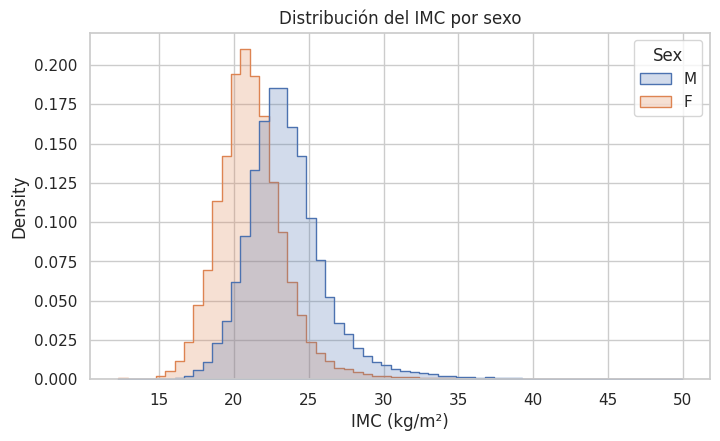

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# --- GRAFICA #1 ---

# 1. Filtrar valores de IMC plausibles
df_IMC = df_fusion[df_fusion["IMC"].between(12, 50)]

# 2. Crear la gráfica
plt.figure(figsize=(8, 4.5))
sns.histplot(data=df_IMC, x="IMC", hue="Sex", bins=60,
             stat="density", common_norm=False, element="step")

# 3. Títulos y ejes
plt.title("Distribución del IMC por sexo")
plt.xlabel("IMC (kg/m²)")

# 4. Guardar y mostrar
plt.savefig("g01_imc_sexo.png", dpi=150, bbox_inches="tight")
plt.show()

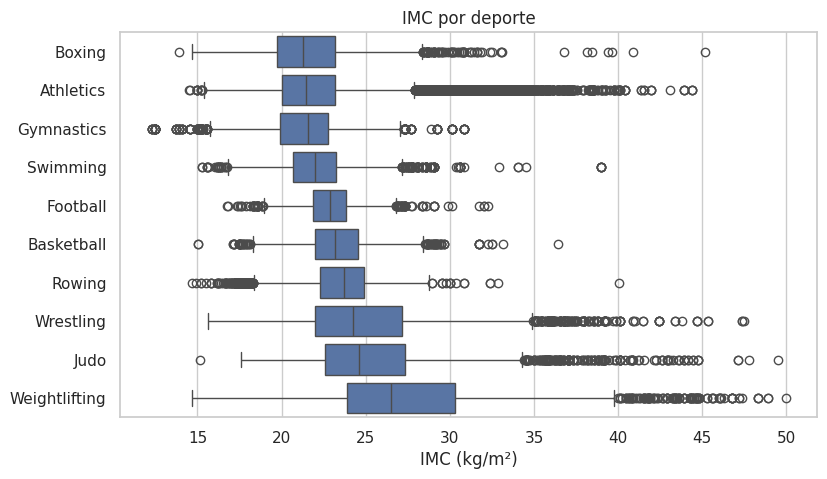

In [ ]:
### ~ ~ ~ GRAFICA #2 ~ ~ ~

# Requiere haber corrido antes el gráfico 1 (ahí se crea d, con IMC entre 12 y 50)

# 1. Elegir los deportes a comparar (10 con cuerpos muy distintos)
deportes = ["Gymnastics", "Athletics", "Swimming", "Football", "Basketball",
            "Rowing", "Judo", "Boxing", "Wrestling", "Weightlifting"]

# 2. Quedarnos solo con las filas de esos deportes
df_IMC_deportes = df_IMC[df_IMC["Sport"].isin(deportes)]

# 3. Calcular el orden: deportes de menor a mayor mediana de IMC
orden = df_IMC_deportes.groupby("Sport")["IMC"].median().sort_values().index

# 4. Crear el lienzo
plt.figure(figsize=(9, 5))

# 5. Dibujar un boxplot horizontal por deporte, en el orden calculado
sns.boxplot(data=df_IMC_deportes, x="IMC", y="Sport", order=orden)

# 6. Títulos y ejes
plt.title("IMC por deporte")
plt.xlabel("IMC (kg/m²)")
plt.ylabel("")  # los nombres de los deportes ya se explican solos

# 7. Guardar (antes de mostrar) y mostrar
plt.savefig("g02_imc_deporte.png", dpi=150, bbox_inches="tight")
plt.show()

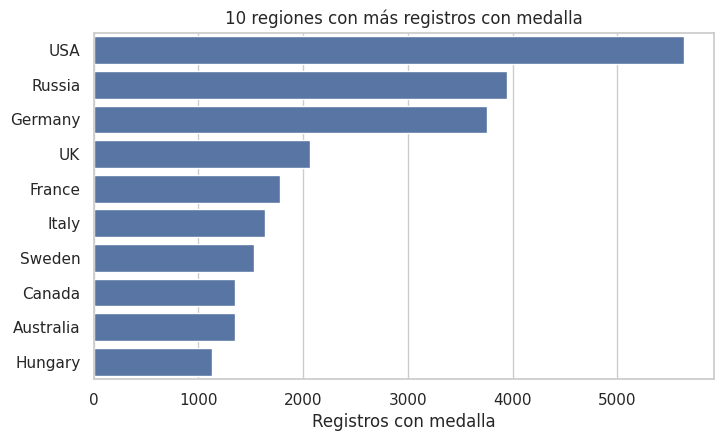

In [ ]:
### ~ ~ ~ GRAFICA #3 ~ ~ ~

# 1. Contar registros con medalla por región y quedarnos con las 10 primeras
top = (df_fusion.groupby("region")["Medalla"]   # agrupar por región, tomar la columna Medalla
       .sum()                                    # sumar los 1 = registros con medalla
       .sort_values(ascending=False)             # de mayor a menor
       .head(10))                                # solo las 10 primeras

# 2. Crear el lienzo
plt.figure(figsize=(8, 4.5))

# 3. Barras horizontales: valores en x, nombres de región en y
sns.barplot(x=top.values, y=top.index, color="#4c72b0")

# 4. Títulos y ejes
plt.title("10 regiones con más registros con medalla")
plt.xlabel("Registros con medalla")
plt.ylabel("")

# 5. Guardar (antes de mostrar) y mostrar
plt.savefig("g03_top_regiones.png", dpi=150, bbox_inches="tight")
plt.show()

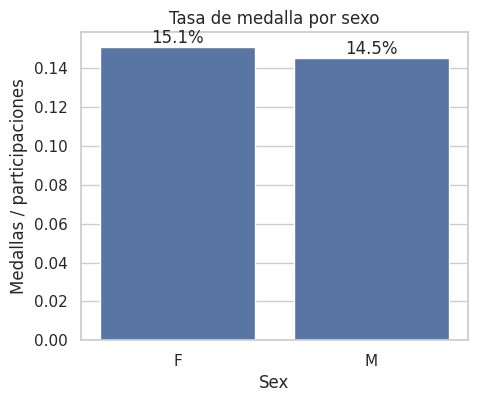

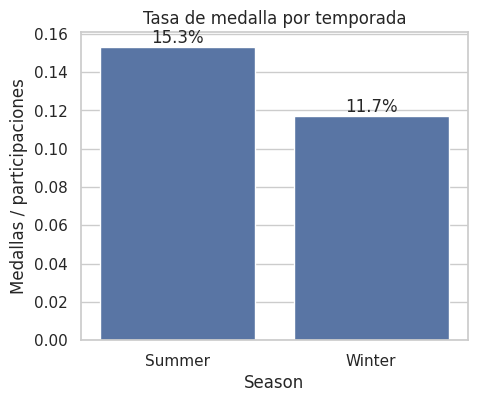

In [ ]:
### ~ ~ ~ GRAFICA #4 ~ ~ ~

# 1. Tasa de medalla por sexo
#    mean() sobre una variable 0/1 = proporción de registros con medalla
t = df_fusion.groupby("Sex")["Medalla"].mean().reset_index()

# 2. Crear el lienzo (pequeño: solo hay 2 barras)
plt.figure(figsize=(5, 4))

# 3. Barras: una por sexo
ax = sns.barplot(data=t, x="Sex", y="Medalla")

# 4. Escribir el porcentaje encima de cada barra
etiquetas = [f"{v*100:.1f}%" for v in t["Medalla"]]
ax.bar_label(ax.containers[0], labels=etiquetas)

# 5. Títulos y ejes
plt.title("Tasa de medalla por sexo")
plt.ylabel("Medallas / participaciones")

# 6. Guardar (antes de mostrar) y mostrar
plt.savefig("g04_tasa_sexo.png", dpi=150, bbox_inches="tight")
plt.show()
print('\n\n\n')
### ~ ~ ~ GRAFICA #5 ~ ~ ~
# 1. Tasa de medalla por temporada (Summer / Winter)
#    mean() sobre una variable 0/1 = proporción de registros con medalla
tasa_temporada = df_fusion.groupby("Season")["Medalla"].mean().reset_index()

# 2. Lienzo pequeño (solo 2 barras)
plt.figure(figsize=(5, 4))

# 3. Una barra por temporada
ax = sns.barplot(data=tasa_temporada, x="Season", y="Medalla")

# 4. Porcentaje encima de cada barra
etiquetas = [f"{v*100:.1f}%" for v in tasa_temporada["Medalla"]]
ax.bar_label(ax.containers[0], labels=etiquetas)

# 5. Títulos y ejes
plt.title("Tasa de medalla por temporada")
plt.ylabel("Medallas / participaciones")

# 6. Guardar (antes de mostrar) y mostrar
plt.savefig("g05_tasa_temporada.png", dpi=150, bbox_inches="tight")
plt.show()

        1960 o después  Antes de 1960
Age           0.005333       0.134727
Height        0.053183       0.790600
Weight        0.056555       0.822819
IMC           0.059214       0.836229


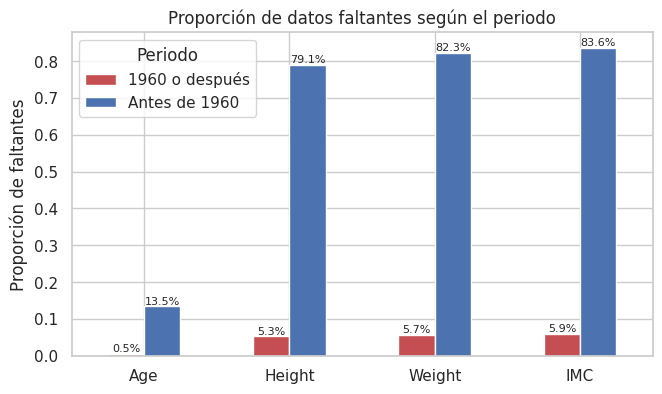

In [ ]:
## ~ ~ ~ GRAFICA 6 ~ ~ ~

import numpy as np
import matplotlib.pyplot as plt

# 1. Variables a revisar y etiqueta de época para cada fila
columnas = ["Age", "Height", "Weight", "IMC"]
periodo = np.where(df_fusion["Year"] < 1960, "Antes de 1960", "1960 o después")

# 2. Proporción de faltantes por época y variable
#    .T = transponer: las variables quedan en filas y las épocas en columnas
falt = df_fusion[columnas].isna().groupby(periodo).mean().T
print(falt)
# 3. Barras agrupadas (una variable en x, una barra por época)
ax = falt.plot(kind="bar", color=["#c44e52", "#4c72b0"], figsize=(7.5, 4.2), rot=0)

# 4. Porcentaje encima de cada barra
for c in ax.containers:
    ax.bar_label(c, labels=[f"{v*100:.1f}%" for v in c.datavalues], fontsize=8)

# 5. Títulos y ejes
ax.set_title("Proporción de datos faltantes según el periodo")
ax.set_ylabel("Proporción de faltantes")
ax.legend(title="Periodo")

# 6. Guardar (antes de mostrar) y mostrar
plt.savefig("g08_faltantes_periodo.png", dpi=150, bbox_inches="tight")
plt.show()

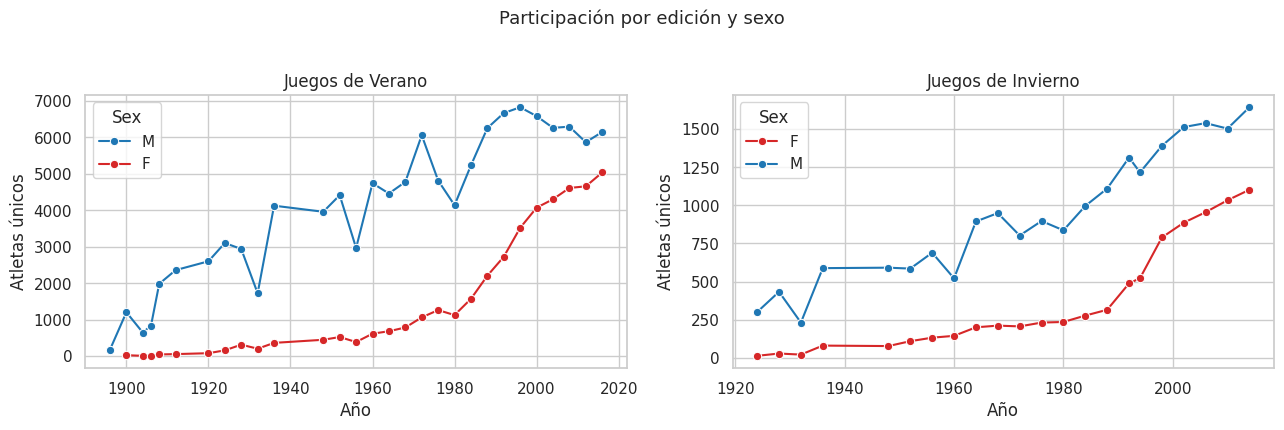

In [ ]:
### ~ ~ ~ GRAFICA #7 ~ ~ ~

# 1. Tabla: atletas únicos por año, temporada y sexo
base = (df_fusion.groupby(["Year", "Season", "Sex"])["ID"]
        .nunique()                       # contar IDs distintos (atletas únicos)
        .reset_index(name="Atletas"))    # volver a tabla, con la columna "Atletas"

# 2. Colores y títulos en diccionarios (así el bucle queda limpio)
colores = {"M": "#1f77b4", "F": "#d62728"}
titulos = {"Summer": "Juegos de Verano", "Winter": "Juegos de Invierno"}

# 3. Figura con 2 paneles lado a lado
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.2))

# 4. Dibujar un panel por temporada
for ax, temporada in zip(ejes, ["Summer", "Winter"]):
    datos = base[base["Season"] == temporada]          # solo esa temporada
    sns.lineplot(data=datos, x="Year", y="Atletas", hue="Sex",
                 marker="o", palette=colores, ax=ax)   # una línea por sexo
    ax.set_title(titulos[temporada])
    ax.set_xlabel("Año")
    ax.set_ylabel("Atletas únicos")

# 5. Título general y ajuste de espacios
fig.suptitle("Participación por edición y sexo", y=1.02, fontsize=13)
plt.tight_layout()

# 6. Guardar (antes de mostrar) y mostrar
plt.savefig("g07_participacion_anio_sexo.png", dpi=150, bbox_inches="tight")
plt.show()